# Beam shaping with the iterative Fourier transform algorithm (IFTA)

A diffractive optical element (DOE) is to shape a laser beam such that a given
intensity pattern appears in the far field (or in the focal plane of a lens).
The element may only change the phase. So we are looking for a phase
$\varphi(x, y)$ with

$$\big|\mathcal{F}\{A_\text{in}\, e^{i\varphi}\}\big|^2 \approx I_\text{target}.$$

The **Gerchberg-Saxton algorithm** jumps back and forth between object and image
plane and imposes the known amplitude in each plane while keeping the phase.
`pyoptics.ifta` implements this as the class `GS`, plus a variant with feedback
(`IFTA_HOO`, hybrid output-output) and `digitize_phase()` for elements with few
phase levels.

In [1]:
import contextlib
import io

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

from pyoptics import ifta
from pyoptics.masks import mask_from_polygon
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

def run_quietly(alg, start):
    """IFTABase.iterate() reports every iteration with print(); we suppress that here."""
    with contextlib.redirect_stdout(io.StringIO()):
        return alg.iterate(start)

## 1. Input beam and target pattern

Input: a Gaussian beam. Target: the letter "F", smoothed (sharp edges cannot be
produced with a finite aperture), somewhat off-centre and normalized to the same
energy as the input (Parseval). Coordinates in pixels.

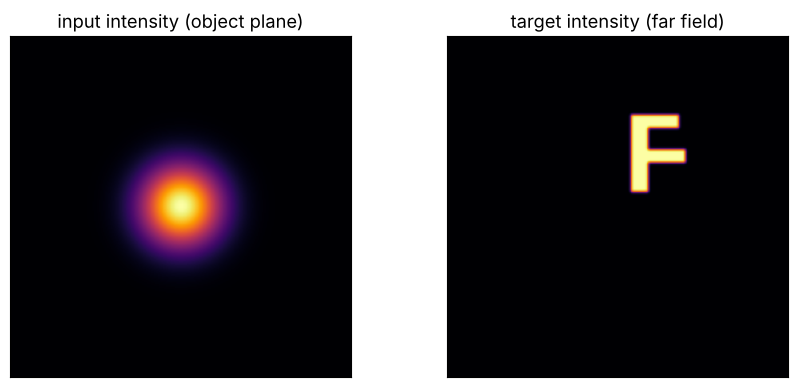

In [2]:
N = 256
x, y, X, Y = grid2d(-N/2, N/2, -N/2, N/2, N)
A_in = np.exp(-(X**2 + Y**2)/(2*30**2))
I_in = A_in**2

F_poly_x = np.array([10, 22, 22, 50, 50, 22, 22, 45, 45, 10])
F_poly_y = np.array([10, 10, 32, 32, 42, 42, 58, 58, 68, 68])
target = mask_from_polygon(x, y, F_poly_x, F_poly_y).astype(float)
target = gaussian_filter(target, 1.0)
I_target = target*np.sum(I_in)/np.sum(target)  # same energy; FT_unitary conserves sum(|U|^2)
support = target > 0.5

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(I_in, cmap="inferno"); axes[0].set_title("input intensity (object plane)")
axes[1].imshow(I_target, cmap="inferno"); axes[1].set_title("target intensity (far field)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

## 2. Gerchberg-Saxton

As figures of merit we use the **efficiency** (fraction of the energy inside the
target region) and the **non-uniformity** (relative standard deviation of the
intensity inside the letter). To record them in every iteration, we replace the
algorithm's stopping condition by a function that logs them, an example of the
modular design of `IFTABase`.

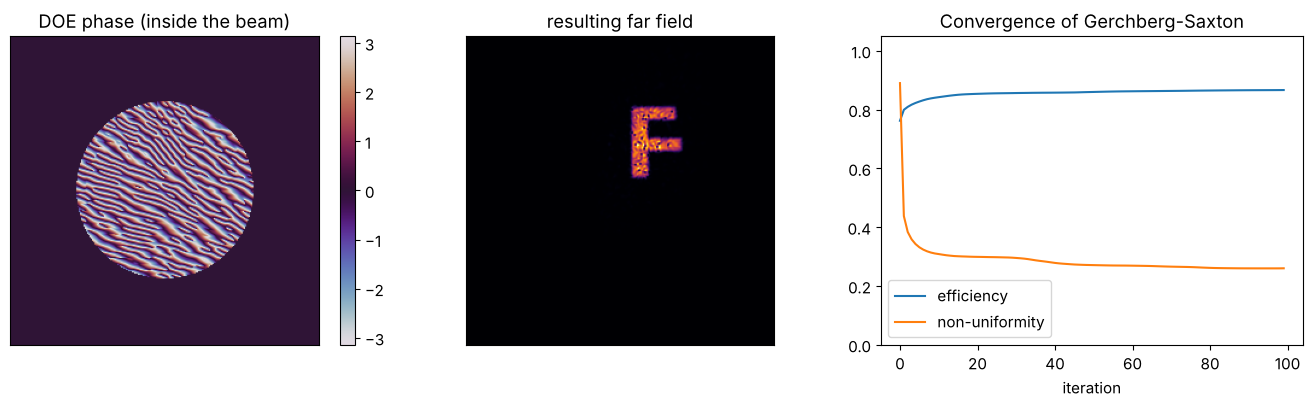

In [3]:
def quality(img):
    I = np.abs(img)**2
    eta = I[support].sum()/I.sum()
    inner = target > 0.9
    nonunif = np.std(I[inner])/np.mean(I[inner])
    return eta, nonunif

def run_logged(alg_class, n_iter, start, **kwargs):
    alg = alg_class(I_in, I_target, n_iter, **kwargs)
    log = []
    def stop(curr_obj, curr_img, old_obj, old_img, i):
        # curr_img has already been overwritten with the target amplitude here, so
        # we compute the actual image from the current object:
        if i > 1:
            log.append(quality(alg.to_image_space(curr_obj, None, None, None, i)))
        return i > n_iter
    alg.stopping_condition = stop
    obj, img, _ = run_quietly(alg, start)
    return obj, alg.to_image_space(obj, None, None, None, 0), np.array(log)

rng = np.random.default_rng(3)
start = np.sqrt(I_target)*np.exp(2j*np.pi*rng.random((N, N)))
obj_gs, img_gs, log_gs = run_logged(ifta.GS, 100, start)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
im = axes[0].imshow(np.angle(obj_gs)*(A_in > 0.05*A_in.max()), cmap="twilight", vmin=-np.pi, vmax=np.pi)
axes[0].set_title("DOE phase (inside the beam)"); fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].imshow(np.abs(img_gs)**2, cmap="inferno"); axes[1].set_title("resulting far field")
for ax in axes[:2]:
    ax.set_xticks([]); ax.set_yticks([])
axes[2].plot(log_gs[:, 0], label="efficiency")
axes[2].plot(log_gs[:, 1], label="non-uniformity")
axes[2].set_xlabel("iteration"); axes[2].set_ylim(0, 1.05); axes[2].legend()
axes[2].set_title("Convergence of Gerchberg-Saxton")
fig.tight_layout()

The far field is **speckled**: where the phase jumps inside the target region,
zeros appear. Gerchberg-Saxton typically gets stuck in such a local minimum after
a few iterations.

## 3. Escaping stagnation: feedback or a better start phase

`IFTA_HOO` mixes the image of the previous iteration with a correction term
(parameter $\beta = 0.9$) to kick the algorithm out of local minima. Another,
often more effective measure is a **smooth start phase**: a random start phase
puts many phase vortices into the target region, whose zeros the algorithm cannot
get rid of anymore. A quadratic start phase (like that of a lens), on the other
hand, creates hardly any vortices.

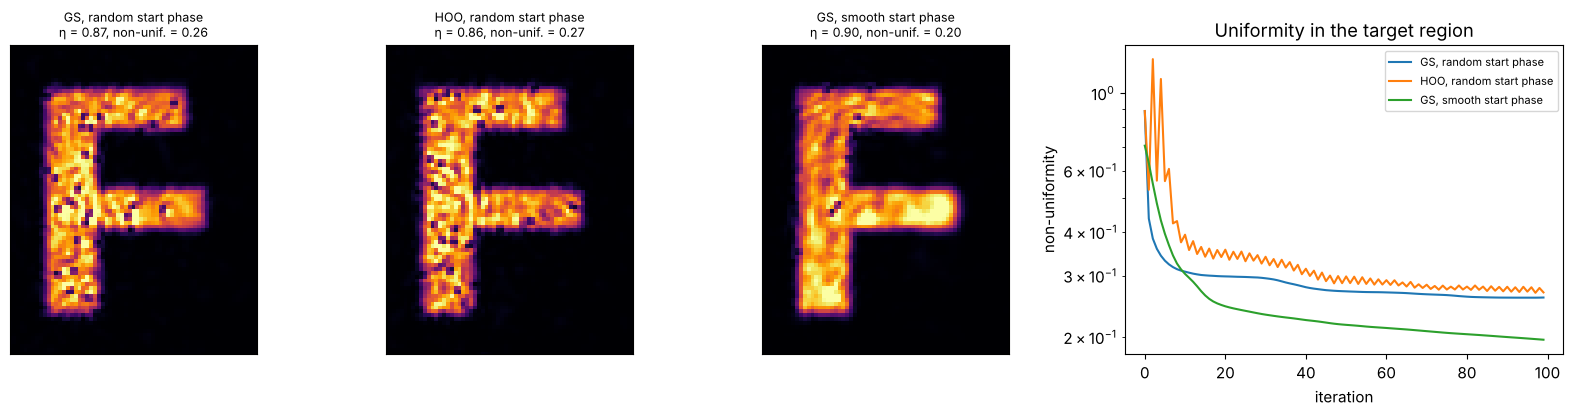

In [4]:
quad_phase = 0.01*((X - 30)**2 + (Y - 39)**2)  # smooth, centred on the "F"
start_smooth = np.sqrt(I_target)*np.exp(1j*quad_phase)
obj_hoo, img_hoo, log_hoo = run_logged(ifta.IFTA_HOO, 100, start)
obj_sm, img_sm, log_sm = run_logged(ifta.GS, 100, start_smooth)

runs = (("GS, random start phase", img_gs, log_gs), ("HOO, random start phase", img_hoo, log_hoo),
        ("GS, smooth start phase", img_sm, log_sm))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
for ax, (name, img, log) in zip(axes, runs):
    I = np.abs(img)**2
    ax.imshow(I, cmap="inferno", vmax=np.percentile(I, 99.9))
    ax.set_xlim(N/2, N/2 + 64); ax.set_ylim(N/2, N/2 + 80); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}\nη = {log[-1, 0]:.2f}, non-unif. = {log[-1, 1]:.2f}", fontsize=9)
    axes[3].plot(log[:, 1], label=name)
axes[3].set_yscale("log"); axes[3].set_xlabel("iteration"); axes[3].set_ylabel("non-uniformity")
axes[3].legend(fontsize=8); axes[3].set_title("Uniformity in the target region")
fig.tight_layout()

In this example, the feedback of HOO helps little, whereas the smooth start phase
gives a visibly more uniform illumination at a somewhat higher efficiency. The
speckle does not vanish completely: the target pattern is sharper than the finite
size of the input beam allows.

## 4. Phase quantization: how many levels does the element need?

Lithographically fabricated DOEs have only $2^n$ phase levels. `digitize_phase()`
rounds the phase accordingly. With only **two** levels the transmission is real,
so its far field is point symmetric: next to the "F", its twin image rotated by
$180°$ appears, and the efficiency can be at most about 40 %. With 4, 8, 16 levels
the result approaches the continuous element. Scalar theory gives
$\mathrm{sinc}^2(1/L)$ for the efficiency of the order the element "aims" at,
with $L$ levels.

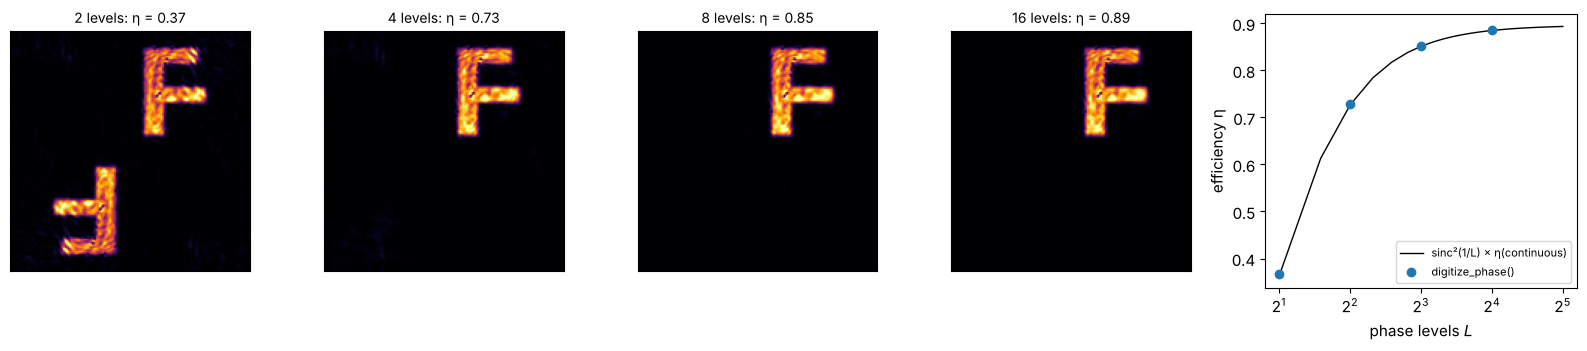

In [5]:
levels = (2, 4, 8, 16)
fig, axes = plt.subplots(1, len(levels) + 1, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1]*len(levels) + [1.3]})
etas = []
for ax, L in zip(axes, levels):
    obj_q = ifta.digitize_phase(obj_sm, L)
    img_q = ifta.FT_unitary(obj_q)
    eta, nonunif = quality(img_q)
    etas.append(eta)
    ax.imshow(np.abs(img_q)**2, cmap="inferno", vmax=np.percentile(np.abs(img_q)**2, 99.9))
    ax.set_title(f"{L} levels: η = {eta:.2f}", fontsize=10)
    ax.set_xlim(N/2 - 80, N/2 + 80); ax.set_ylim(N/2 - 80, N/2 + 80); ax.set_xticks([]); ax.set_yticks([])
Ls = np.arange(2, 33)
axes[-1].plot(Ls, np.sinc(1/Ls)**2*log_sm[-1, 0], "k-", lw=1, label="sinc²(1/L) × η(continuous)")
axes[-1].plot(levels, etas, "o", label="digitize_phase()")
axes[-1].set_xscale("log", base=2); axes[-1].set_xlabel("phase levels $L$"); axes[-1].set_ylabel("efficiency η")
axes[-1].legend(fontsize=8)
fig.tight_layout()